# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión B

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Néstor Iram Zaragoza Sánchez  
**Grupo:** 512  **Fecha:** 26/10/2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la cantidad de pasajeros y la distancia recorrida?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`passenger_count`** y **`trip_distance`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_B_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_B/
└── notebooks/
    └── Examen_B_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("../data/raw/nyc_taxi_examen.csv")

print("Primeras cinco filas:")
print(df.head())
print("Dimensiones:", df.shape)
print("\nNombres de columnas:")
print(df.columns.tolist())
print("\nTipos de datos:")
print(df.dtypes)

print("\nResumen estadístico de columnas numéricas:")
print(df.describe())

print("\nValores únicos en payment_type:")
print(df["payment_type"].unique())

print("\nFrecuencia de cada payment_type:")
print(df["payment_type"].value_counts(dropna=False))


Primeras cinco filas:
   Unnamed: 0  VendorID tpep_pickup_datetime tpep_dropoff_datetime  \
0           0         1  2026-08-01 00:03:04   2026-08-01 00:07:51   
1           1         1  2026-08-01 00:38:45   2026-08-01 00:44:02   
2           2         1                  NaN   2026-08-01 01:01:07   
3           3         1  2026-08-01 00:27:35   2026-08-01 00:54:27   
4           4         2  2026-08-01 00:39:08   2026-08-01 01:00:23   

   passenger_count  trip_distance  RatecodeID  PULocationID  DOLocationID  \
0              1.0           0.60         1.0         140.0         262.0   
1              1.0           0.70         1.0         140.0         262.0   
2            100.0           1.10         1.0         140.0         263.0   
3              1.0           5.24         1.0         164.0          80.0   
4              1.0           3.57         1.0         148.0         141.0   

  payment_type  ...  extra  mta_tax  tip_amount  tolls_amount  \
0  Credit card  ...    3.5   

         Unnamed: 0      VendorID  passenger_count  trip_distance  \
count  2.427612e+06  2.427612e+06     2.415489e+06   2.415470e+06   
mean   1.213806e+06  1.888167e+00     1.296144e+00   3.300702e+00   
std    7.007914e+05  8.086844e-01     1.881923e+00   5.167909e+00   
min    0.000000e+00  1.000000e+00    -5.000000e+00  -9.998763e+01   
25%    6.069028e+05  2.000000e+00     1.000000e+00   9.900000e-01   
50%    1.213806e+06  2.000000e+00     1.000000e+00   1.700000e+00   
75%    1.820708e+06  2.000000e+00     1.000000e+00   3.360000e+00   
max    2.427611e+06  7.000000e+00     1.000000e+02   1.686490e+03   

         RatecodeID  PULocationID  DOLocationID   fare_amount         extra  \
count  2.415474e+06  2.415487e+06  2.415475e+06  2.415488e+06  2.415487e+06   
mean   4.229419e+00  1.641392e+02  1.632236e+02  3.852567e+01  1.567837e+00   
std    1.720220e+01  6.285386e+01  6.925613e+01  5.423764e+02  1.906552e+00   
min    1.000000e+00  1.000000e+00  1.000000e+00 -1.849600e+03 

payment_type
Credit card    2051983
Cash            329533
Dispute          23558
NaN              12125
No charge        10413
Name: count, dtype: int64


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [2]:
df_limpio = df.copy()

print("Dimensiones antes de limpiar:", df_limpio.shape)
print("\nValores nulos por columna (antes):")
print(df_limpio.isnull().sum())
print("\nRegistros duplicados (antes):", df_limpio.duplicated().sum())

df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.dropna()

df_limpio = df_limpio[
    (df_limpio["trip_distance"] > 0)
    & (df_limpio["passenger_count"] > 0) & (df_limpio["passenger_count"] < 100)
    & (df_limpio["fare_amount"] > 0) & (df_limpio["fare_amount"] < 10000)
    & (df_limpio["trip_duration"] > 0)
].copy()

print("\nDimensiones después de limpiar:", df_limpio.shape)
print("Registros que quedan:", len(df_limpio))

Dimensiones antes de limpiar:

 (2427612, 21)

Valores nulos por columna (antes):


Unnamed: 0                   0
VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64



Registros duplicados (antes): 0



Dimensiones después de limpiar: (2107024, 21)
Registros que quedan: 2107024


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`passenger_count`** y **`trip_distance`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [3]:
df_cash = df_limpio[df_limpio["payment_type"] == "Cash"].copy()
X = df_cash[["passenger_count", "trip_distance"]]

print("Cantidad de viajes pagados en efectivo:", len(df_cash))
display(X.describe())


Cantidad de viajes pagados en efectivo: 283537


,passenger_count,trip_distance
count,283537.000000,283537.000000
mean,1.343786,3.842333
std,0.758948,6.210980
min,1.000000,0.010000
25%,1.000000,0.920000
50%,1.000000,1.700000
75%,1.000000,4.370000
max,6.000000,1686.490000


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [4]:
X_log = np.log1p(X)

scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_log)

print("Variables transformadas (log1p):")
display(X_log.describe())

X_escalado_df = pd.DataFrame(X_escalado, columns=["passenger_count", "trip_distance"])
print("Variables estandarizadas:")
display(X_escalado_df.describe())


Variables transformadas (log1p):


,passenger_count,trip_distance
count,283537.000000,283537.000000
mean,0.814740,1.225452
std,0.250236,0.763307
min,0.693147,0.009950
25%,0.693147,0.652325
50%,0.693147,0.993252
75%,0.693147,1.680828
max,1.945910,7.430997


Variables estandarizadas:


,passenger_count,trip_distance
count,2.835370e+05,2.835370e+05
mean,-3.432213e-16,1.395339e-16
std,1.000002e+00,1.000002e+00
min,-4.859139e-01,-1.592418e+00
25%,-4.859139e-01,-7.508485e-01
50%,-4.859139e-01,-3.042034e-01
75%,-4.859139e-01,5.965843e-01
max,4.520428e+00,8.129834e+00


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

,k,Inercia,Silueta
0,2,326248.01,0.5502
1,3,161175.26,0.5921
2,4,115676.03,0.6086
3,5,87354.81,0.6155
4,6,61467.32,0.5529


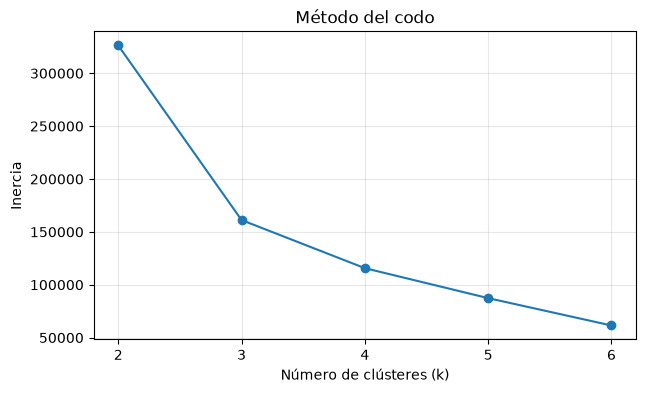

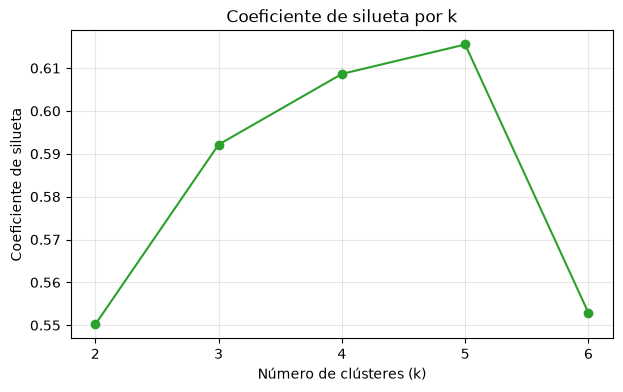

In [5]:
ks = [2, 3, 4, 5, 6]
inercias, siluetas = [], []

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_k = km.fit_predict(X_escalado)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_escalado, etiquetas_k,
                                     sample_size=5000, random_state=42))

tabla_k = pd.DataFrame({"k": ks, "Inercia": inercias, "Silueta": siluetas})
display(tabla_k.round({"Inercia": 2, "Silueta": 4}))

plt.figure(figsize=(7, 4))
plt.plot(ks, inercias, marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(ks); plt.grid(alpha=0.3); plt.show()

plt.figure(figsize=(7, 4))
plt.plot(ks, siluetas, marker="o", color="tab:green")
plt.title("Coeficiente de silueta por k")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(ks); plt.grid(alpha=0.3); plt.show()


## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`passenger_count`**, eje Y = **`trip_distance`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

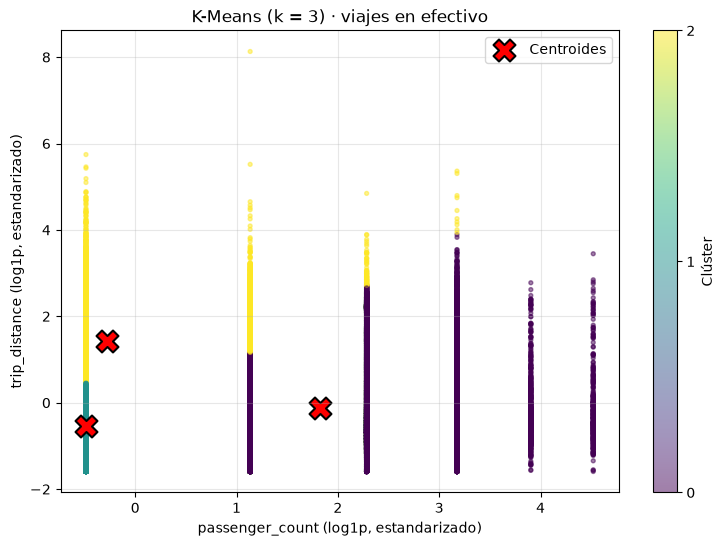

In [6]:
# k=3: codo marcado, silueta de 0.5921 y tres perfiles interpretables.
# k=5 logra la mayor silueta (0.6155), pero elijo una segmentación más sencilla.
k_final = 3

kmeans_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
etiquetas = kmeans_final.fit_predict(X_escalado)

plt.figure(figsize=(9, 6))
puntos = plt.scatter(X_escalado[:, 0], X_escalado[:, 1], c=etiquetas,
            cmap="viridis", s=8, alpha=0.5)
plt.colorbar(puntos, ticks=range(k_final), label="Clúster")
plt.scatter(kmeans_final.cluster_centers_[:, 0], kmeans_final.cluster_centers_[:, 1],
            marker="X", s=250, c="red", edgecolors="black", linewidths=1.5,
            label="Centroides")
plt.title(f"K-Means (k = {k_final}) · viajes en efectivo")
plt.xlabel("passenger_count (log1p, estandarizado)")
plt.ylabel("trip_distance (log1p, estandarizado)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `passenger_count`.
   - **Media y mediana** de `trip_distance`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: número de pasajeros y millas para la distancia.

**Evidencia:** tabla de estadísticos por clúster.

In [7]:
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas

tabla_clusters = df_resultado.groupby("cluster").agg(
    viajes=("trip_distance", "size"),
    pasajeros_media=("passenger_count", "mean"),
    pasajeros_mediana=("passenger_count", "median"),
    distancia_media_millas=("trip_distance", "mean"),
    distancia_mediana_millas=("trip_distance", "median"),
)
display(tabla_clusters.round(2))


,viajes,pasajeros_media,pasajeros_mediana,distancia_media_millas,distancia_mediana_millas
cluster,,,,,
0,53782,2.66,2.0,3.15,1.60
1,164305,1.00,1.0,1.40,1.20
2,65450,1.13,1.0,10.53,8.87


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos. 

**Respuesta:** Elegí `k = 3` porque la gráfica del codo muestra su cambio de pendiente más claro en ese punto: la inercia baja de 326,248.01 con `k = 2` a 161,175.26 con `k = 3`, una reducción del 50.60 %. Al pasar a `k = 4`, baja a 115,676.03, por lo que la mejora absoluta ya es bastante menor. Además, la silueta sube de 0.5502 a 0.5921. Reconozco que la silueta máxima corresponde a `k = 5` (0.6155), pero su ventaja frente a tres grupos es de 0.0234. Prefiero tres grupos como equilibrio entre el codo, la separación obtenida y una interpretación sencilla: viajes individuales cortos, viajes de varios pasajeros y viajes largos con pocos pasajeros. No elijo tres porque tenga la menor inercia ni porque maximice la silueta.


**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:** Los estadísticos están expresados en pasajeros y millas originales. Identifico estos perfiles:

- **Clúster 0 — Viajes de varios pasajeros, mayormente cortos:** contiene 53,782 viajes. Tiene una media de 2.66 pasajeros y una mediana de 2.00; la distancia media es de 3.15 millas y la mediana de 1.60. La diferencia entre media y mediana de distancia indica que algunos recorridos largos elevan el promedio.
- **Clúster 1 — Viajes individuales cortos:** contiene 164,305 viajes, por lo que es el grupo más numeroso. Tanto la media como la mediana son de 1.00 pasajero. La distancia media es de 1.40 millas y la mediana de 1.20; es el perfil con los recorridos más cortos en promedio.
- **Clúster 2 — Viajes largos con pocos pasajeros:** contiene 65,450 viajes. La media es de 1.13 pasajeros y la mediana de 1.00. Su distancia media es de 10.53 millas y la mediana de 8.87, las mayores entre los tres grupos.


**Pregunta 3 — Análisis sencillo.** ¿Qué diferencias encuentras entre los grupos con menor y mayor cantidad promedio de pasajeros? Apóyate en la tabla.

**Respuesta:** El clúster 1 tiene el menor promedio de pasajeros (1.00), mientras que el clúster 0 tiene el mayor (2.66). El segundo transporta, en promedio, 1.66 pasajeros más por viaje. También recorre más distancia en promedio: 3.15 frente a 1.40 millas, una diferencia aproximada de 1.75 millas. Sin embargo, las medianas de distancia son más cercanas (1.60 frente a 1.20 millas), así que la diferencia en los viajes típicos es menor que la diferencia entre promedios. El grupo de mayor ocupación tiene 53,782 viajes y el de menor ocupación tiene 164,305.


**Pregunta 4 — Análisis sencillo.** ¿Los viajes con más pasajeros son siempre los de mayor distancia? Explica qué muestran tus clústeres, sin asumir que todos los viajes se comportan igual.

**Respuesta:** No. El clúster 0 tiene la mayor cantidad promedio de pasajeros (2.66), pero su distancia media es de 3.15 millas. En cambio, el clúster 2 tiene solo 1.13 pasajeros en promedio y recorre 10.53 millas; sus medianas también contrastan: 1.60 y 8.87 millas, respectivamente. La dispersión muestra distintas distancias para una misma cantidad de pasajeros. Por ello, una mayor ocupación no garantiza un viaje más largo; los grupos resumen tendencias y no describen de forma idéntica todos los viajes.

---
### Lista de verificación antes de entregar

- [x] Se muestran la carga, exploración, limpieza y filtrado.
- [x] Se utilizaron las **dos variables indicadas**.
- [x] Se aplicaron `log1p` y `StandardScaler`.
- [x] Se calcularon inercia y silueta para `k = 2...6`.
- [x] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [x] Se visualizan los clústeres y sus centroides.
- [x] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [x] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**